In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, DBSCAN

In [2]:

# Point to a real CSV file, not the notebook
Data_Link = r"D:\mahmoud\My_Courses\R5_Machine_Learning_Microsoft_AI_Data_Science\ENG Baraa\Self_Learning_Unsupervised_Learning\delivery_operations_students.csv"

df = pd.read_csv(Data_Link)
df.head()

,order_id,distance_km,delivery_time_min,preparation_time_min,order_value_egp
0,DLV-0001,2.2,14,22,206
1,DLV-0002,2.1,17,12,190
2,DLV-0003,2.2,12,8,119
3,DLV-0004,2.0,22,11,113
4,DLV-0005,9.8,50,22,292


In [3]:
DF_Cluster_Data = df[['distance_km', 'delivery_time_min']].copy()
DF_Cluster_Data.head()

,distance_km,delivery_time_min
0,2.2,14
1,2.1,17
2,2.2,12
3,2.0,22
4,9.8,50


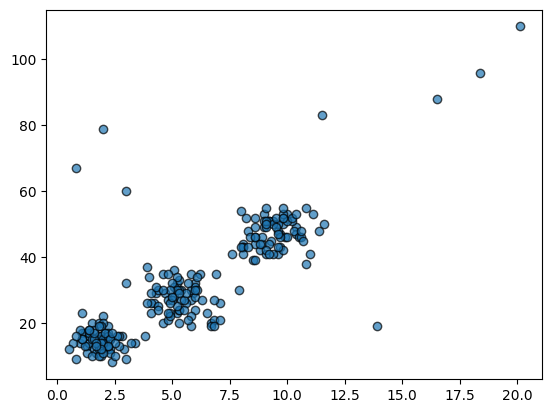

In [14]:
plt.scatter(DF_Cluster_Data['distance_km'], DF_Cluster_Data["delivery_time_min"],ec = 'black',alpha = 0.7)
plt.show()

In [15]:
kmeans = KMeans(n_clusters=4 , random_state=42,n_init= 10, max_iter=300 )

X = DF_Cluster_Data[["distance_km","delivery_time_min"]]
kmeans.fit(X)

,n_clusters,4
,init,'k-means++'
,n_init,10
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


In [18]:
DF_Cluster_Data["kmeans_cluster"] = kmeans.labels_
DF_Cluster_Data

,distance_km,delivery_time_min,kmeans_cluster
0,2.2,14,0
1,2.1,17,0
2,2.2,12,0
3,2.0,22,0
4,9.8,50,1
...,...,...,...
228,6.5,23,2
229,9.8,55,1
230,1.9,12,0
231,9.1,50,1


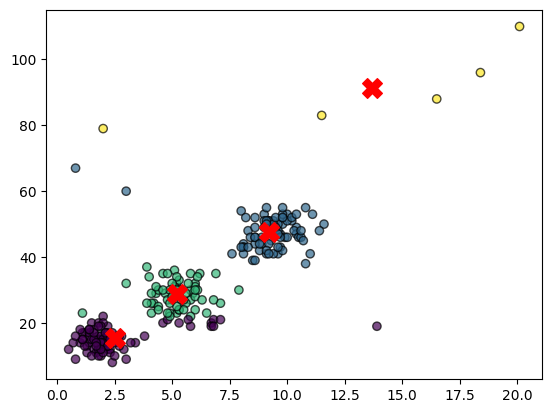

In [ ]:
plt.scatter(
    DF_Cluster_Data["distance_km"],
    DF_Cluster_Data["delivery_time_min"],
    c=DF_Cluster_Data["kmeans_cluster"],
    ec='black',
    alpha=0.7,
)
plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    s=200,
    marker="X",
    c="red",
)
plt.show()

In [20]:
DF_Cluster_Data["kmeans_cluster"] = kmeans.labels_
DF_Cluster_Data

,distance_km,delivery_time_min,kmeans_cluster
0,2.2,14,0
1,2.1,17,0
2,2.2,12,0
3,2.0,22,0
4,9.8,50,1
...,...,...,...
228,6.5,23,2
229,9.8,55,1
230,1.9,12,0
231,9.1,50,1


In [21]:
kmeans.n_iter_

6

In [22]:
kmeans.inertia_

5268.248649859944

In [25]:
inertias = []
for k in range(1,9):
  model = KMeans(n_clusters= k , random_state=42,n_init= 10, max_iter=300 )
  model.fit(X)
  inertias.append(model.inertia_)
  

In [26]:
inertias

[68147.3573390558,
 21122.76312480025,
 11635.329919295671,
 5268.248649859944,
 3972.1168989441926,
 2914.733882188249,
 2246.8141183555904,
 1913.9473638262323]

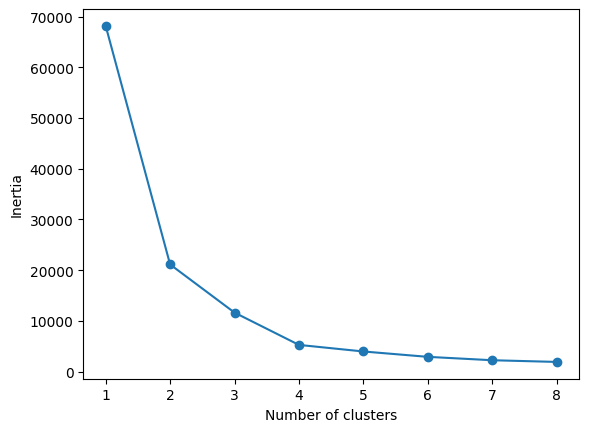

In [27]:
plt.plot(range(1,9),inertias,marker="o")
plt.xlabel("Number of clusters")
plt.ylabel("Inertia")
plt.show()

In [28]:
DF_Cluster_Data

,distance_km,delivery_time_min,kmeans_cluster
0,2.2,14,0
1,2.1,17,0
2,2.2,12,0
3,2.0,22,0
4,9.8,50,1
...,...,...,...
228,6.5,23,2
229,9.8,55,1
230,1.9,12,0
231,9.1,50,1


In [29]:
DF_Cluster_Data.groupby("kmeans_cluster").mean()

,distance_km,delivery_time_min
kmeans_cluster,,
0,2.518824,15.282353
1,9.223377,47.623377
2,5.190909,28.651515
3,13.700000,91.200000


In [30]:
DF_Cluster_Data.groupby("kmeans_cluster").mean()

,distance_km,delivery_time_min
kmeans_cluster,,
0,2.518824,15.282353
1,9.223377,47.623377
2,5.190909,28.651515
3,13.700000,91.200000


In [31]:
DF_Cluster_Data["kmeans_cluster"].value_counts()

kmeans_cluster
0    85
1    77
2    66
3     5
Name: count, dtype: int64

In [32]:
X

,distance_km,delivery_time_min
0,2.2,14
1,2.1,17
2,2.2,12
3,2.0,22
4,9.8,50
...,...,...
228,6.5,23
229,9.8,55
230,1.9,12
231,9.1,50


In [33]:
from sklearn.cluster import DBSCAN
dbscan = DBSCAN(eps = 2 , min_samples = 4)
dbscan.fit(X)
DF_Cluster_Data["DBSCAN_Clusters"] = dbscan.labels_
DF_Cluster_Data

,distance_km,delivery_time_min,kmeans_cluster,DBSCAN_Clusters
0,2.2,14,0,0
1,2.1,17,0,0
2,2.2,12,0,0
3,2.0,22,0,0
4,9.8,50,1,1
...,...,...,...,...
228,6.5,23,2,2
229,9.8,55,1,1
230,1.9,12,0,0
231,9.1,50,1,1


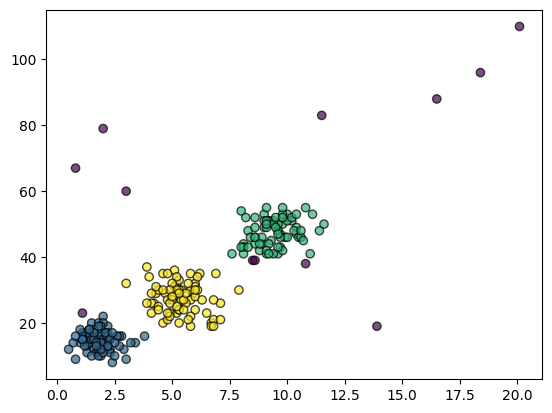

In [36]:
plt.scatter(DF_Cluster_Data["distance_km"], DF_Cluster_Data["delivery_time_min"],c=DF_Cluster_Data["DBSCAN_Clusters"],
            ec = 'black',alpha = 0.7)
plt.show()

In [38]:
noise_point = (DF_Cluster_Data["DBSCAN_Clusters"] == -1)
noise_point

0      False
1      False
2      False
3      False
4      False
       ...  
228    False
229    False
230    False
231    False
232    False
Name: DBSCAN_Clusters, Length: 233, dtype: bool

In [39]:
dbscan.core_sample_indices_

array([  0,   1,   2,   4,   5,   6,   7,   8,   9,  10,  11,  12,  13,
        14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,  26,
        27,  28,  29,  30,  31,  33,  34,  35,  36,  37,  38,  41,  42,
        44,  45,  46,  47,  48,  49,  51,  52,  53,  54,  55,  56,  57,
        58,  59,  60,  61,  62,  63,  64,  65,  66,  67,  68,  69,  70,
        71,  72,  73,  74,  75,  76,  77,  78,  79,  80,  81,  82,  83,
        84,  85,  86,  87,  88,  90,  91,  92,  94,  96,  97,  98,  99,
       100, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113,
       114, 115, 116, 117, 118, 120, 121, 122, 123, 124, 125, 126, 127,
       128, 129, 130, 131, 132, 133, 134, 135, 136, 138, 139, 140, 141,
       142, 144, 145, 146, 147, 148, 149, 151, 152, 153, 154, 155, 157,
       158, 159, 160, 161, 162, 164, 165, 166, 167, 168, 169, 170, 171,
       172, 173, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185,
       186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 19

In [40]:
point_types = ["Border"] * len(X)
point_types

['Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',
 'Border',

In [41]:
for i in dbscan.core_sample_indices_:
  point_types[i] = "Core"
point_types

['Core',
 'Core',
 'Core',
 'Border',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Border',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Border',
 'Border',
 'Core',
 'Core',
 'Border',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Border',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Border',
 'Core',
 'Core',
 'Core',
 'Border',
 'Core',
 'Border',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Border',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',

In [42]:
for i,label in enumerate(dbscan.labels_):
  if label == -1:
    point_types[i] = "Noise"

In [43]:
point_types

['Core',
 'Core',
 'Core',
 'Border',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Border',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Border',
 'Noise',
 'Core',
 'Core',
 'Noise',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Border',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Noise',
 'Core',
 'Core',
 'Core',
 'Noise',
 'Core',
 'Noise',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Noise',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Core',
 'Cor

In [44]:
DF_Cluster_Data["point_type"] = point_types
DF_Cluster_Data

,distance_km,delivery_time_min,kmeans_cluster,DBSCAN_Clusters,point_type
0,2.2,14,0,0,Core
1,2.1,17,0,0,Core
2,2.2,12,0,0,Core
3,2.0,22,0,0,Border
4,9.8,50,1,1,Core
...,...,...,...,...,...
228,6.5,23,2,2,Core
229,9.8,55,1,1,Core
230,1.9,12,0,0,Core
231,9.1,50,1,1,Core


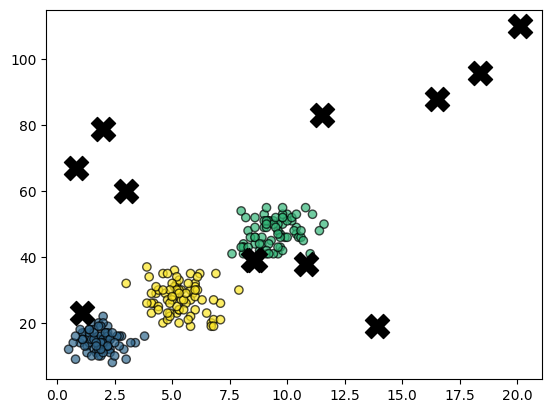

In [49]:
plt.scatter(
    DF_Cluster_Data['distance_km'],
    DF_Cluster_Data['delivery_time_min'],
    c=DF_Cluster_Data['DBSCAN_Clusters'],
    ec='black',
    alpha=0.7,
)
plt.scatter(
    DF_Cluster_Data[noise_point]['distance_km'],
    DF_Cluster_Data[noise_point]['delivery_time_min'],
    marker='X',
    color='black',
    s=300,
)
plt.show()

In [50]:
DF_Cluster_Data

,distance_km,delivery_time_min,kmeans_cluster,DBSCAN_Clusters,point_type
0,2.2,14,0,0,Core
1,2.1,17,0,0,Core
2,2.2,12,0,0,Core
3,2.0,22,0,0,Border
4,9.8,50,1,1,Core
...,...,...,...,...,...
228,6.5,23,2,2,Core
229,9.8,55,1,1,Core
230,1.9,12,0,0,Core
231,9.1,50,1,1,Core


In [52]:
# compare bettween KMeans , DBSCAN
DF_Cluster_Data.groupby("kmeans_cluster").agg(

    Customer_count = ("kmeans_cluster","count"),
    AVG_Distance_Km = ("distance_km", "mean"),
    AVG_Delivery_Time_Min = ("delivery_time_min", "mean"),
    )

,Customer_count,AVG_Distance_Km,AVG_Delivery_Time_Min
kmeans_cluster,,,
0,85,2.518824,15.282353
1,77,9.223377,47.623377
2,66,5.190909,28.651515
3,5,13.700000,91.200000


In [53]:
# compare bettween KMeans , DBSCAN
DF_Cluster_Data.groupby("DBSCAN_Clusters").agg(

    Customer_count = ("kmeans_cluster","count"),
    AVG_Distance_Km = ("distance_km", "mean"),
    AVG_Delivery_Time_Min = ("delivery_time_min", "mean"),
    )

,Customer_count,AVG_Distance_Km,AVG_Delivery_Time_Min
DBSCAN_Clusters,,,
-1,12,9.600000,61.750000
0,74,1.890541,14.581081
1,72,9.423611,47.555556
2,75,5.357333,27.586667


In [ ]:
# Side-by-side comparison of KMeans and DBSCAN
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# KMeans plot
axes[0].scatter(
    DF_Cluster_Data["distance_km"],
    DF_Cluster_Data["delivery_time_min"],
    c=DF_Cluster_Data["kmeans_cluster"],
    cmap="tab10",
    edgecolors="black",
    alpha=0.7,
)
axes[0].scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    s=200,
    marker="X",
    c="red",
)
axes[0].set_title("KMeans Clustering")
axes[0].set_xlabel("Distance (km)")
axes[0].set_ylabel("Delivery Time (min)")

# DBSCAN plot
noise_mask = DF_Cluster_Data["DBSCAN_Clusters"] == -1
axes[1].scatter(
    DF_Cluster_Data.loc[~noise_mask, "distance_km"],
    DF_Cluster_Data.loc[~noise_mask, "delivery_time_min"],
    c=DF_Cluster_Data.loc[~noise_mask, "DBSCAN_Clusters"],
    cmap="tab10",
    edgecolors="black",
    alpha=0.7,
)
axes[1].scatter(
    DF_Cluster_Data.loc[noise_mask, "distance_km"],
    DF_Cluster_Data.loc[noise_mask, "delivery_time_min"],
    color="black",
    marker="X",
    s=100,
)
axes[1].set_title("DBSCAN Clustering")
axes[1].set_xlabel("Distance (km)")
axes[1].set_ylabel("Delivery Time (min)")

plt.tight_layout()
plt.show()